# Как собраны новости и что вошло в анализ

Корпус новостей собран для разработки ассистента букмекерского трейдера. В этих материалах мы рассчитываем находить сведения о травмах и восстановлении игроков, составах, дисквалификациях, подготовке команд и условиях проведения матчей.

Однако прежде чем анализировать содержание, необходимо проверить сами данные: **сколько публикаций удалось собрать, какие источники и даты представлены, сохранились ли тексты и есть ли среди них повторы**. Именно этим вопросам посвящён данный этап исследования.

Проверка достоверности сообщений и их связи с конкретными матчами будет проводиться отдельно. Для текущего анализа календарь матчей не требуется.

## Как работает сборщик

Сбор новостей проходит в несколько этапов:

**Поиск ссылок → загрузка страниц → извлечение текста → проверка даты и формата → предварительный отбор материалов об АПЛ → сохранение.**

Способ поиска зависит от сайта: используются новостные ленты, разделы с публикациями, открытые интерфейсы или карты сайта со ссылками на страницы. Количество просматриваемых страниц ограничено, поэтому в корпус попадают не все материалы выбранных изданий.

Из каждой загруженной страницы программа извлекает заголовок, текст, даты публикации и обновления, если они указаны. Если текст статьи получить не удалось, может быть сохранён только анонс из новостной ленты. Извлечение не всегда работает точно: вместе с основным текстом иногда сохраняются реклама, рекомендации других материалов и сведения об авторе.

## Как отбираются материалы

Предварительная связь с АПЛ определяется по упоминаниям лиги и клубов из словаря. Программа ищет их в тематических метках сайта, заголовке и начале текста.

Такой подход помогает выделить потенциально подходящие материалы, но не гарантирует их релевантность. Например, историческая статья может пройти отбор благодаря названию клуба в заголовке. Напротив, новость об игроке может не пройти его, если в тексте явно не названа команда.

По результатам проверок сохранённые материалы распределяются по группам:

| Группа | Какие материалы в неё попадают |
|---|---|
| **Исключённые материалы** | Страницы, которые программа определила как видео, онлайн-трансляции, профили игроков, тексты не на английском языке или другие страницы без признаков статьи |
| **Неполные материалы** | Материалы подходящего формата, для которых удалось сохранить только анонс или текст, не прошедший проверку полноты |
| **Для дополнительной проверки** | Материалы, прошедшие проверку полноты текста, но с неясной датой публикации или недостаточными признаками связи с АПЛ |
| **Отобранные статьи** | Статьи, прошедшие все проверки сборщика и включённые в основной корпус |

Проверки выполняются в порядке, указанном в таблице. Каждая запись попадает только в одну итоговую группу. Например, материал с неполным текстом и неясной связью с АПЛ будет отнесён к неполным, поскольку полнота проверяется раньше.

Для коротких постов предусмотрено отдельное хранение. Сборщик присваивает отметку **«полный текст»**, если выполнены три условия:

- сохранено не менее 180 символов;
- текст извлечён из содержимого материала, а не только из анонса;
- на странице нет указания, что для доступа требуется подписка.

Однако прохождение этих проверок не гарантирует, что статья извлечена целиком и без лишних фрагментов. Поэтому в EDA мы проверяем, встречаются ли среди сохранённых текстов обрезанные статьи, реклама и другие элементы страницы.

## Почему не все сохранённые записи вошли в корпус

Результаты сбора представлены в двух видах:

- **Метаданные** — сведения о материалах: источник, ссылка, заголовок, даты и результат отбора. Тексты статей в этих файлах не хранятся.
- **Основной корпус `epl_news`** — отобранные статьи вместе с извлечёнными текстами.

В доступных метаданных содержится **7 427 записей**. Из них в основной корпус вошли **4 515**:

| Результат отбора | Количество записей | Входит в `epl_news` |
|---|---:|:---:|
| Отобранные статьи | 4 515 | Да |
| Для дополнительной проверки | 2 378 | Нет |
| Неполные материалы | 264 | Нет |
| Исключённые материалы | 270 | Нет |
| **Всего** | **7 427** | |

## EDA
Далее последовательно рассмотрим объём и состав корпуса, распределение материалов по источникам и датам, качество извлечённых текстов и повторы. Эти результаты помогут определить, какие данные готовы к анализу содержания, а какие требуют очистки или дополнительной проверки.

In [13]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Показывать все столбцы.
pd.set_option("display.max_columns", None)

# Не обрезать содержимое ячеек.
pd.set_option("display.max_colwidth", None)


# Ноутбук находится в корне проекта или в папке EDA / notebooks.
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent

# Новости.
news = pd.read_csv(
    ROOT / "data/epl_news_2026-10-26_2026-11-08.csv",
    encoding="utf-8-sig",
)

# Метаданные всех источников.
metadata_files = sorted((ROOT / "data").glob("*/metadata.csv"))

metadata = pd.concat(
    [
        pd.read_csv(path, encoding="utf-8-sig").assign(
            metadata_folder=path.parent.name
        )
        for path in metadata_files
    ],
    ignore_index=True,
)

# Настройки отображения.
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)

plt.rcParams["figure.figsize"] = (10, 5)

## Как читать таблицы: записи и публикации

В таблицах мы считаем **записи — строки в загруженных файлах**. Каждая запись относится к материалу из определённого источника. Это не число попыток скачивания и не обязательно число отдельных публикаций: одна ссылка может встречаться в нескольких строках.

Метаданные содержат сведения обо всех сохранённых группах материалов, а основной корпус `news` — только об отобранных статьях. Ниже показано распределение записей по группам. Затем по сочетанию источника и ссылки проверяется, совпадает ли состав основного корпуса с группой «Отобранные статьи».

Если материал есть в метаданных, но отсутствует в основном корпусе, это само по себе не означает ошибку загрузки. Он мог не пройти отбор или быть оставлен для дополнительной проверки.

In [9]:
# Заполняем пропуски только в полях, используемых для отбора.
selection_fields = [
    "exclusion_reason",
    "text_status",
    "selection_status",
    "content_type",
]

metadata[selection_fields] = metadata[selection_fields].fillna("")


# Порядок условий соответствует правилам сборщика.
def get_group(row):
    if row["exclusion_reason"].strip():
        return "Исключённые материалы"
    if row["text_status"] != "full_text":
        return "Неполные материалы"
    if row["selection_status"] != "included":
        return "Для дополнительной проверки"
    if row["content_type"] == "post":
        return "Короткие сообщения"
    return "Отобранные статьи"


metadata["Группа"] = metadata.apply(get_group, axis=1)

# Показываем количество записей в каждой группе.
group_counts = (
    metadata["Группа"]
    .value_counts()
    .rename_axis("Группа")
    .to_frame("Количество записей")
)

group_counts.loc["Всего"] = group_counts.sum()

display(group_counts)

# Проверяем, что основной корпус совпадает с отобранной группой.
keys = ["source_id", "url"]
selected = metadata.loc[
    metadata["Группа"].eq("Отобранные статьи"), keys
]

for frame in [news, selected]:
    assert frame[keys].notna().all().all(), "Есть записи без источника или URL."
    assert not frame.duplicated(keys).any(), "Повторяется сочетание источника и URL."

assert set(map(tuple, selected.to_numpy())) == set(
    map(tuple, news[keys].to_numpy())
), "Основной корпус отличается от группы отобранных статей."

,Количество записей
Группа,
Отобранные статьи,4515
Для дополнительной проверки,2378
Исключённые материалы,270
Неполные материалы,264
Всего,7427


## Что мы собрали?

Сравним все сохранённые материалы с основным корпусом:
посчитаем записи, уникальные ссылки и источники.

Затем проверим, сколько записей основного корпуса содержит
текст и как часто повторяются ссылки.

Одна ссылка может встречаться несколько раз, поэтому число
строк не равно числу отдельных публикаций. При этом повторение
ссылки ещё не означает, что сохранённые тексты одинаковы.

Непустой текст также не гарантирует, что статья извлечена
полностью. Его качество проверим отдельно.

In [11]:
# Пустые строки и строки из пробелов считаем пропусками.
news_urls = news["url"].fillna("").str.strip()
metadata_urls = metadata["url"].fillna("").str.strip()
news_texts = news["text"].fillna("").str.strip()

has_text = news_texts.ne("")

summary = pd.DataFrame({
    "Показатель": [
        "Количество записей",
        "Количество уникальных непустых ссылок",
        "Количество источников",
    ],
    "Все сохранённые материалы": [
        len(metadata),
        metadata_urls[metadata_urls.ne("")].nunique(),
        metadata["source_id"].nunique(),
    ],
    "Основной корпус": [
        len(news),
        news_urls[news_urls.ne("")].nunique(),
        news["source_id"].nunique(),
    ],
})

display(summary)

text_summary = pd.DataFrame({
    "Показатель": [
        "Записи с непустым текстом",
        "Записи без текста",
        "Уникальные ссылки хотя бы с одним непустым текстом",
        "Дополнительные записи по уже встречающимся ссылкам",
    ],
    "Количество": [
        int(has_text.sum()),
        int((~has_text).sum()),
        news_urls[has_text & news_urls.ne("")].nunique(),
        int(news_urls.ne("").sum())
        - news_urls[news_urls.ne("")].nunique(),
    ],
})

display(text_summary)

,Показатель,Все сохранённые материалы,Основной корпус
0,Количество записей,7427,4515
1,Количество уникальных непустых ссылок,7097,4384
2,Количество источников,25,21


,Показатель,Количество
0,Записи с непустым текстом,4515
1,Записи без текста,0
2,Уникальные ссылки хотя бы с одним непустым текстом,4384
3,Дополнительные записи по уже встречающимся ссылкам,131


### Выводы и рекомендации блока

В основной корпус вошли **4 515 записей из 21 источника**.
Они содержат **4 384 уникальные ссылки**. Все записи имеют
непустой текст, однако его полноту и качество ещё нужно проверить.

По результатам таблиц можно выделить три направления работы:

1. **Разобраться с повторяющимися ссылками.**
   В корпусе есть 131 дополнительная запись по уже встречающимся
   адресам. Нужно сравнить их тексты: одинаковые записи можно
   не учитывать повторно, а различающиеся — сохранить
   для анализа версий. При подсчёте публикаций следует учитывать
   каждую ссылку один раз.

2. **Проверить причины отсутствия четырёх источников в корпусе.**
   В метаданных представлены 25 источников, а в основном корпусе — 21.
   Нужно посмотреть, почему материалы остальных источников
   не прошли отбор: из-за неподходящего содержания, неполного текста
   или необходимости дополнительной проверки.
   Само отсутствие источника в корпусе не доказывает ошибку сбора.

3. **Проверить качество непустых текстов.**
   Пустых текстов в основном корпусе нет. Следующий шаг —
   посмотреть распределение их длины и прочитать несколько
   коротких, длинных и обычных материалов из разных источников.
   Это поможет обнаружить анонсы вместо статей, обрезанные тексты,
   рекламу и другие посторонние фрагменты.

Из 7 427 сохранённых записей в основной корпус вошли 4 515.
Эту разницу нельзя считать количеством неудачных загрузок:
часть материалов не вошла в корпус по правилам отбора.
Отсутствие пустых текстов также характеризует только
отобранный корпус, а не успешность сбора в целом.

### 1. Какие сайты представлены в корпусе?

Сборщик может найти статью как на сайте самого издания,
так и через агрегатор — площадку, которая собирает ссылки
на чужие публикации. Например, ссылка может быть найдена
через LiveScore, но вести на статью Sky Sports.

В следующей таблице статьи сгруппированы по сайту,
на который ведёт ссылка. В таком примере публикация
будет учтена у Sky Sports.

Если одна ссылка встретилась несколько раз, учитываем её
только один раз. Для каждого сайта показываем количество
уникальных ссылок и их долю среди всех уникальных ссылок
на материалы с текстом в основном корпусе.

Так мы увидим, какие сайты дали больше всего публикаций
для дальнейшего анализа.

,Все сохранённые ссылки,Ссылки с текстом в основном корпусе,"Доля с текстом, %"
Источник сбора,,,
LiveScore,1210,580,47.9
Sports Mole,1019,562,55.2
GOAL,740,152,20.5
Football Insider,630,515,81.7
Mirror,460,336,73.0
Manchester Evening News,426,291,68.3
TEAMtalk,384,349,90.9
CaughtOffside,350,329,94.0
Football London,322,289,89.8


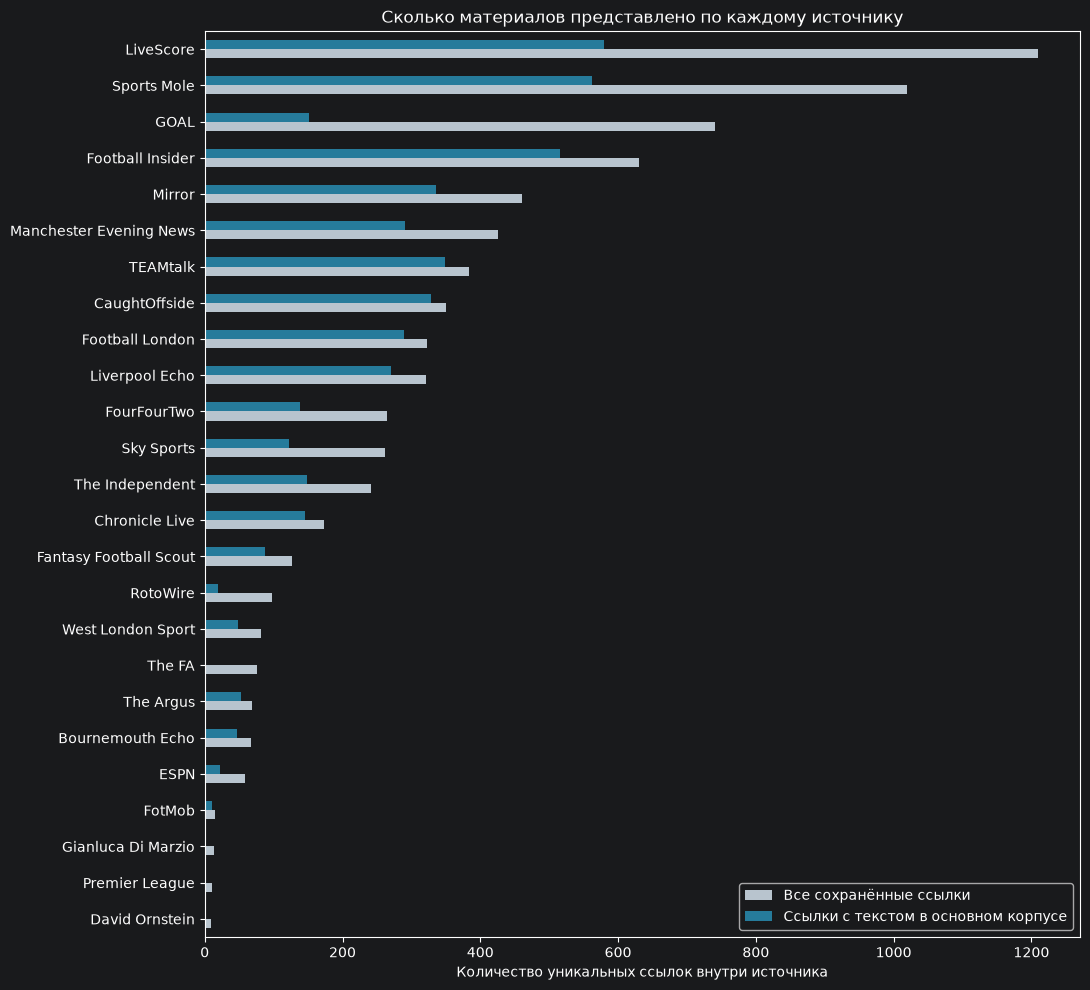

In [14]:
# Подготавливаем ссылки для подсчёта.
source_metadata = metadata.assign(
    url=metadata["url"].fillna("").str.strip()
)
source_news = news.assign(
    url=news["url"].fillna("").str.strip()
)

source_metadata = source_metadata.loc[source_metadata["url"].ne("")]

# Учитываем только материалы основного корпуса с непустым текстом.
has_text = source_news["text"].fillna("").str.strip().ne("")
source_news = source_news.loc[has_text & source_news["url"].ne("")]

# Считаем уникальные ссылки внутри каждого источника.
source_summary = pd.DataFrame({
    "Все сохранённые ссылки":
        source_metadata.groupby("source_id")["url"].nunique(),
    "Ссылки с текстом в основном корпусе":
        source_news.groupby("source_id")["url"].nunique(),
}).fillna(0).astype(int)

source_summary["Доля с текстом, %"] = (
    source_summary["Ссылки с текстом в основном корпусе"]
    / source_summary["Все сохранённые ссылки"]
    * 100
).round(1)

source_summary = source_summary.sort_values(
    "Все сохранённые ссылки", ascending=False
)

# Подставляем названия источников вместо технических идентификаторов.
source_names = metadata.drop_duplicates("source_id").set_index("source_id")["source"]
source_summary.index = [
    source_names.get(source_id, source_id)
    for source_id in source_summary.index
]
source_summary.index.name = "Источник сбора"

display(source_summary)

# Столбцы расположены рядом, а не сложены.
source_summary.iloc[::-1, :2].plot.barh(
    figsize=(11, max(5, len(source_summary) * 0.4)),
    color=["#b8c4ce", "#267b9b"],
)

plt.title("Сколько материалов представлено по каждому источнику")
plt.xlabel("Количество уникальных ссылок внутри источника")
plt.ylabel("")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

### Выводы и рекомендации блока

Источники представлены в корпусе неравномерно. Больше всего
материалов с текстом получено через LiveScore — **580**,
Sports Mole — **562** и Football Insider — **515**.
Для сравнения, через ESPN получено **22**, а через FotMob — **10**.
Поэтому общие результаты анализа содержания будут сильнее зависеть
от крупных источников.

Доля сохранённых ссылок, вошедших в основной корпус с текстом,
также различается. У CaughtOffside она составляет **94,0%**,
у TEAMtalk — **90,9%**, у Football London — **89,8%**.
У GOAL этот показатель равен **20,5%**, а у RotoWire — **19,4%**.

Эти различия не позволяют напрямую оценить качество парсера.
Материал мог не попасть в корпус из-за ошибки извлечения,
неподходящего формата или правил отбора по АПЛ.
Высокая доля включения также не гарантирует чистоту текста
и полезность статьи.

Четыре источника представлены только в метаданных:
**The FA, Gianluca Di Marzio, Premier League и David Ornstein**.
Причины отсутствия их материалов в основном корпусе
нужно рассмотреть отдельно.

### 2. За какой период собраны материалы?

Посмотрим, за какие дни в корпусе есть публикации и как
распределяется их количество.

Сначала проверим даты: сколько значений удалось прочитать,
сколько отсутствует и сколько требует уточнения.
Для графика используем только даты с указанным часовым поясом,
переведённые в московское время. Датой загрузки их не заменяем.

Количество публикаций по дням характеризует собранный корпус,
а не весь новостной поток. Небольшое число материалов за день
может объясняться как активностью изданий, так и неполным сбором.

In [17]:
from datetime import datetime, timezone, timedelta

MSK = timezone(timedelta(hours=3))


def parse_date(value):
    if pd.isna(value) or not str(value).strip():
        return None, "Дата отсутствует"

    try:
        date = datetime.fromisoformat(
            str(value).strip().replace("Z", "+00:00")
        )
    except ValueError:
        return None, "Не удалось прочитать"

    if date.utcoffset() is None:
        return None, "Не указан часовой пояс"

    return date.astimezone(MSK), "Дата прочитана"


# Разбираем даты один раз для каждого набора.
news_dates = pd.DataFrame(
    news["published_at"].map(parse_date).tolist(),
    columns=["Дата публикации, МСК", "Статус даты"],
    index=news.index,
)

metadata_dates = pd.DataFrame(
    metadata["published_at"].map(parse_date).tolist(),
    columns=["Дата публикации, МСК", "Статус даты"],
    index=metadata.index,
)

date_statuses = [
    "Дата прочитана",
    "Дата отсутствует",
    "Не удалось прочитать",
    "Не указан часовой пояс",
]

date_quality = pd.DataFrame({
    "Все сохранённые материалы":
        metadata_dates["Статус даты"].value_counts(),
    "Основной корпус":
        news_dates["Статус даты"].value_counts(),
}).reindex(date_statuses).fillna(0).astype(int)

date_quality.index.name = "Результат проверки"
date_quality.loc["Всего"] = date_quality.sum()

display(date_quality)

,Все сохранённые материалы,Основной корпус
Результат проверки,,
Дата прочитана,7115,4515
Дата отсутствует,312,0
Не удалось прочитать,0,0
Не указан часовой пояс,0,0
Всего,7427,4515


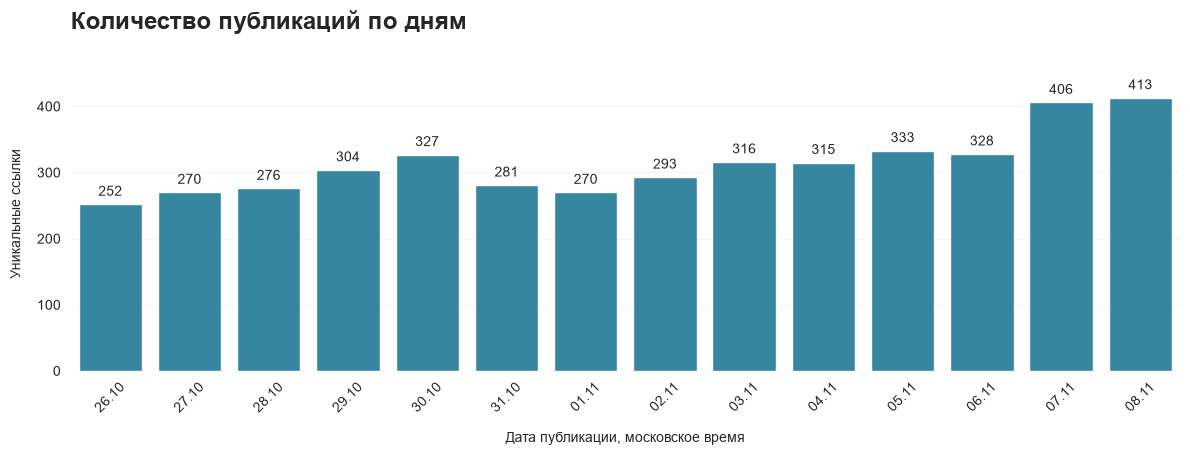

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Подготавливаем данные для графика.
plot_data = daily_counts.rename_axis("date").reset_index(name="count")
plot_data["day"] = plot_data["date"].dt.strftime("%d.%m")

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(12, 5))

    sns.barplot(
        data=plot_data,
        x="day",
        y="count",
        color="#3686A0",
        saturation=1,
        ax=ax,
    )

    # Количество публикаций над каждым столбцом.
    ax.bar_label(ax.containers[0], padding=4, fontsize=10)

    ax.set_title(
        "Количество публикаций по дням",
        loc="left",
        fontsize=17,
        fontweight="bold",
        pad=20,
    )
    ax.set_xlabel("Дата публикации, московское время", labelpad=12)
    ax.set_ylabel("Уникальные ссылки", labelpad=10)

    ax.set_ylim(0, max(1, plot_data["count"].max()) * 1.15)
    ax.tick_params(axis="x", rotation=45)
    ax.set_axisbelow(True)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=0.3)

    sns.despine(ax=ax, left=True, bottom=True)


    plt.tight_layout(rect=[0, 0.07, 1, 1])
    plt.show()

### 3. Какие источники представлены не за весь период?

Реализованный период сбора — с 26 октября по 8 ноября,
то есть 14 дней. Ниже показаны источники, у которых
в основном корпусе есть публикации не за каждый день
этого периода.

Таблица помогает найти ограничения временного охвата.
Она не устанавливает их причину: материалы могли отсутствовать
на сайте, не попасть в поиск или не пройти отбор.

In [24]:
# Подготавливаем данные, сохраняя исходный корпус без изменений.
source_dates = news.assign(
    url=news["url"].fillna("").str.strip(),
    text_length=news["text"].fillna("").str.strip().str.len(),
    publication_date=news_dates["Дата публикации, МСК"],
)

# Одна запись на сочетание источника и ссылки.
source_dates = (
    source_dates.loc[source_dates["url"].ne("")]
    .sort_values("text_length", ascending=False, kind="stable")
    .drop_duplicates(["source_id", "url"])
)

# Количество ссылок, включая записи с неизвестной датой.
total_urls = source_dates.groupby("source_id")["url"].nunique()

# Для анализа периода используем только распознанные даты.
valid = source_dates.dropna(subset=["publication_date"]).copy()
valid["day"] = valid["publication_date"].map(lambda date: date.date())

periods = valid.groupby("source_id").agg(
    dated_urls=("url", "nunique"),
    first_day=("day", "min"),
    last_day=("day", "max"),
    active_days=("day", "nunique"),
)

source_periods = total_urls.rename("Всего ссылок").to_frame().join(periods)

# Источники без подходящих дат тоже остаются в таблице.
for column in ["dated_urls", "active_days"]:
    source_periods[column] = source_periods[column].fillna(0).astype(int)

source_periods["Без подходящей даты"] = (
    source_periods["Всего ссылок"] - source_periods["dated_urls"]
)

source_periods = source_periods.sort_values(
    "Всего ссылок", ascending=False
)

for column in ["first_day", "last_day"]:
    source_periods[column] = source_periods[column].map(
        lambda date: date.strftime("%d.%m.%Y")
        if pd.notna(date) else "Нет данных"
    )

# Понятные названия источников.
names = news.drop_duplicates("source_id").set_index("source_id")["source"]
source_periods.index = [
    names.get(source_id, source_id)
    for source_id in source_periods.index
]
source_periods.index.name = "Источник"

source_periods = source_periods.rename(columns={
    "dated_urls": "Ссылок с подходящей датой",
    "first_day": "Первая публикация",
    "last_day": "Последняя публикация",
    "active_days": "Дней с публикациями",
})

display(source_periods)

,Всего ссылок,Ссылок с подходящей датой,Первая публикация,Последняя публикация,Дней с публикациями,Без подходящей даты
Источник,,,,,,
LiveScore,580,580,29.10.2026,08.11.2026,11,0
Sports Mole,562,562,26.10.2026,08.11.2026,14,0
Football Insider,515,515,26.10.2026,08.11.2026,14,0
TEAMtalk,349,349,26.10.2026,08.11.2026,14,0
Mirror,336,336,26.10.2026,08.11.2026,14,0
CaughtOffside,329,329,26.10.2026,08.11.2026,14,0
Manchester Evening News,291,291,26.10.2026,08.11.2026,14,0
Football London,289,289,26.10.2026,08.11.2026,14,0
Liverpool Echo,271,271,26.10.2026,08.11.2026,14,0


### Выводы и рекомендации блока

Для всех источников собраны новости за 14 дней —
с 26 октября по 8 ноября. Однако в основной корпус вошли
материалы за разные периоды. Например, у ESPN представлены
только 7–8 ноября, у GOAL — 4–8 ноября,
а у Bournemouth Echo — 1–8 ноября.

Поэтому небольшое количество статей не обязательно означает,
что источник редко публикует новости. Возможно, сборщик нашёл
только последние материалы или более ранние статьи не прошли отбор.

Чтобы выяснить причину, нужно проверить:

1. **Есть ли более ранние статьи в метаданных?**
   Если есть, посмотреть, почему они не вошли в основной корпус.

2. **Если их нет в метаданных, доступны ли они на сайте?**
   Если доступны, проверить, доходит ли сборщик до нужных дат
   при просмотре архива. Возможно, поиск останавливается слишком рано.

Начать стоит с ESPN, GOAL и Bournemouth Echo:
у них в корпусе отсутствуют материалы за начало выбранного периода.

Пока эти различия не устранены, сравнивать источники только
по общему количеству статей недостаточно: для одних собраны
два дня, для других — все четырнадцать.

При этом наличие статей за каждый день ещё не означает,
что сбор полный. Оно подтверждает только то, что за каждый
день найдена хотя бы одна публикация.

### 4. Есть ли пропуски в данных?

Проверим, у всех ли записей есть заголовок, ссылка, источник
и дата публикации. Для основного корпуса также проверим наличие текста.

Пустыми считаем отсутствующие значения, пустые строки и строки,
состоящие только из пробелов.

Метаданные не содержат текстов статей по своей структуре,
поэтому отсутствие столбца с текстом в них не является ошибкой.

In [25]:
fields = {
    "title": "Заголовок",
    "url": "Ссылка",
    "source_id": "Идентификатор источника",
    "source": "Название источника",
    "published_at": "Дата публикации",
}


def missing_summary(frame, columns):
    # Учитываем как NaN, так и пустые строки и пробелы.
    missing = frame[list(columns)].replace(
        r"^\s*$", pd.NA, regex=True
    ).isna()

    result = pd.DataFrame({
        "Пропусков": missing.sum(),
        "Доля записей с пропуском, %": (
            missing.mean() * 100
        ).round(1),
    })

    return result.rename(index=columns).rename_axis("Поле")


# Основной корпус: проверяем также текст.
news_missing = missing_summary(news, {**fields, "text": "Текст"})
display(news_missing)

# Метаданные: проверяем только предусмотренные в них поля.
metadata_missing = missing_summary(metadata, fields)
display(metadata_missing)

,Пропусков,"Доля записей с пропуском, %"
Поле,,
Заголовок,0,0.0
Ссылка,0,0.0
Идентификатор источника,0,0.0
Название источника,0,0.0
Дата публикации,0,0.0
Текст,0,0.0


,Пропусков,"Доля записей с пропуском, %"
Поле,,
Заголовок,0,0.0
Ссылка,0,0.0
Идентификатор источника,0,0.0
Название источника,0,0.0
Дата публикации,312,4.2


### Выводы и рекомендации блока
В основном корпусе пропусков в проверенных полях нет:
у всех записей есть заголовок, текст, ссылка, источник
и дата публикации. Заполнять пропуски или удалять строки
по этому признаку не требуется.

В метаданных дата публикации отсутствует у **312 записей —
4,2% от общего количества**. Остальные проверенные поля заполнены.
Поскольку метаданные включают материалы, не прошедшие отбор,
отсутствие пропусков в основном корпусе не означает,
что сборщик всегда успешно извлекает даты.

Для улучшения сбора рекомендуется:

1. **Определить, у каких источников отсутствуют даты.**
   Это поможет понять, связана ли проблема с отдельными сайтами.

2. **Проверить несколько таких страниц.**
   Если дата есть на сайте, нужно уточнить правила её извлечения.
   Если дата не указана, оставить пропуск и сохранить причину.
   Подставлять дату загрузки вместо даты публикации нельзя.

3. **Сохранить материалы без даты для анализа содержания.**
   Их не следует автоматически удалять: текст может быть полезен.
   Однако без уточнения даты такие записи нельзя включать
   в распределение публикаций по дням.

### 5. Какой длины тексты в корпусе?

Посмотрим, насколько различается объём публикаций.
Для каждой статьи посчитаем количество слов, разделяя текст
по пробелам и переносам строк. Это приблизительная оценка:
остатки HTML-разметки и ошибки извлечения могут влиять на результат.

Каждая ссылка учитывается один раз. Таблица покажет минимальную,
максимальную и типичные длины, а график — распределение статей
по диапазонам.

Особое внимание уделим текстам короче 100 и длиннее 2 000 слов.
Эти границы нужны только для выбора примеров на просмотр,
а не для автоматического удаления статей.

In [27]:
# Количество слов в каждом выбранном тексте.
word_counts = news["text"].fillna("").str.split().str.len()

# Основные характеристики длины.
length_summary = (
    word_counts.describe(percentiles=[0.1, 0.5, 0.9, 0.99])
    .loc[["min", "10%", "50%", "90%", "99%", "max"]]
    .rename(index={
        "min": "Самый короткий текст",
        "10%": "10% текстов не длиннее",
        "50%": "Медиана: половина текстов не длиннее",
        "90%": "90% текстов не длиннее",
        "99%": "99% текстов не длиннее",
        "max": "Самый длинный текст",
    })
    .round(1)
    .to_frame("Количество слов")
)

display(length_summary)

# Тексты, которые стоит посмотреть отдельно.
review_summary = pd.DataFrame({
    "Группа": ["Короче 100 слов", "Длиннее 2 000 слов"],
    "Количество": [
        int((word_counts < 100).sum()),
        int((word_counts > 2000).sum()),
    ],
})

review_summary["Доля текстов, %"] = (
    review_summary["Количество"] / len(word_counts) * 100
).round(1)

display(review_summary)

,Количество слов
Самый короткий текст,21.0
10% текстов не длиннее,288.0
Медиана: половина текстов не длиннее,482.0
90% текстов не длиннее,829.6
99% текстов не длиннее,1488.9
Самый длинный текст,6530.0


,Группа,Количество,"Доля текстов, %"
0,Короче 100 слов,47,1.0
1,Длиннее 2 000 слов,12,0.3


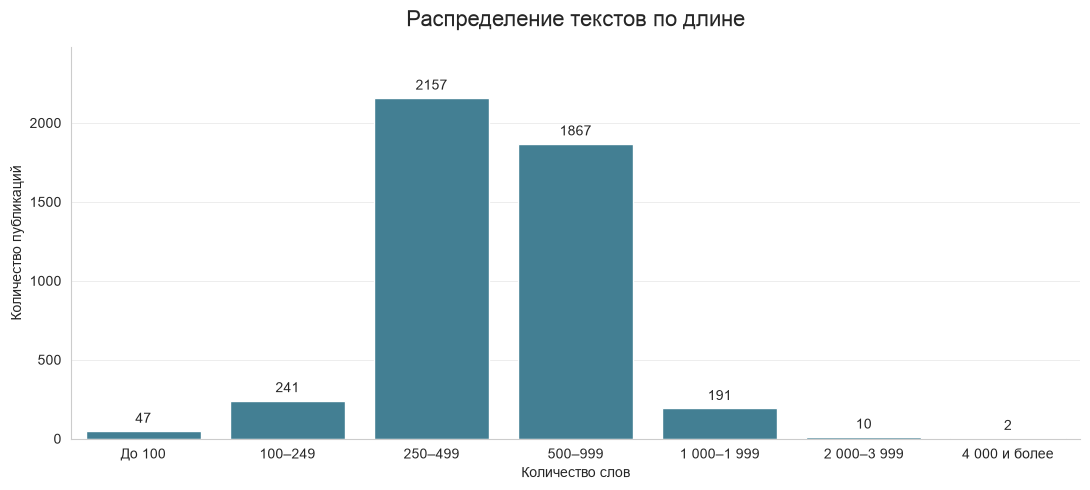

In [29]:
labels = [
    "До 100",
    "100–249",
    "250–499",
    "500–999",
    "1 000–1 999",
    "2 000–3 999",
    "4 000 и более",
]

# Распределяем длины по диапазонам.
length_groups = pd.cut(
    word_counts,
    bins=[0, 100, 250, 500, 1000, 2000, 4000, float("inf")],
    labels=labels,
    right=False,
)

distribution = (
    length_groups.value_counts(sort=False)
    .rename_axis("Диапазон")
    .reset_index(name="Количество")
)

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(11, 5))

    sns.barplot(
        data=distribution,
        x="Диапазон",
        y="Количество",
        order=labels,
        color="#3686A0",
        ax=ax,
    )

    ax.bar_label(ax.containers[0], padding=4, fmt="%.0f")
    ax.set_title("Распределение текстов по длине", fontsize=16, pad=15)
    ax.set_xlabel("Количество слов")
    ax.set_ylabel("Количество публикаций")
    ax.margins(y=0.15)
    ax.grid(axis="x", visible=False)

    sns.despine()
    plt.tight_layout()
    plt.show()

### Вывод

Большинство текстов содержит от 250 до 999 слов. Коротких
материалов менее 100 слов — 47, а длинных, от 2 000 слов, — 12.

Эти тексты стоит просмотреть: короткие могут оказаться анонсами
или обрезанными статьями, а длинные — содержать лишние элементы
страницы. Однако сама длина не является основанием для удаления.

### 6. Проверка качества текстов на примерах

Чтобы понять, насколько правильно извлечены статьи,
рассмотрим несколько заранее выбранных материалов:
короткие, длинные и содержащие подозрительные фрагменты.

Проверим, не попали ли в текст реклама, технические команды
и другие элементы страницы. Также посмотрим, всегда ли
необычная длина или отдельные фразы указывают на проблему.

Для каждого примера приведём наблюдение и рекомендацию.
Такая проверка поможет выявить виды ошибок, но не позволит
оценить их долю во всём корпусе.

In [31]:
selected_ids = [
    "e906a04db4ce926d29a79a4d",
    "1ea12655f224a1aa886e80fa",
    "8e839cb8382a019828a8f8fd",
    "8d7691dc3c67a36788837252",
    "91b19c27993a4a63e326a025",
    "05d28bda2ae9a66f59d86c35",
    "e5a2c4e85956cc03aa2122cb",
    "366f472514e85bfd42e6c2e3",
    "fb98dd8b28b34bc125e1e4e3",
]

review_examples = news.loc[
    news["document_id"].isin(selected_ids)
].copy()

review_examples["Количество слов"] = (
    review_examples["text"].fillna("").str.split().str.len()
)

review_examples = review_examples.reset_index(drop=True)

display(
    review_examples[
        ["document_id", "source", "title", "Количество слов"]
    ].rename(columns={
        "document_id": "ID",
        "source": "Источник",
        "title": "Заголовок",
    })
)

,ID,Источник,Заголовок,Количество слов
0,8d7691dc3c67a36788837252,Football Insider,Everton 'definitely' holding Marcus Rashford 'talks' as January move on the cards,483
1,e906a04db4ce926d29a79a4d,LiveScore,Ipswich Town await Hull team news,21
2,8e839cb8382a019828a8f8fd,Chronicle Live,Granit Xhaka speaks out on Sunderland form as criticism mounts - 'There is no chance',483
3,fb98dd8b28b34bc125e1e4e3,The Independent,Arsenal receive huge boost as William Saliba returns to training,171
4,05d28bda2ae9a66f59d86c35,Bournemouth Echo,James Hill and Marco Rose's Sparta Praha press conference,2077
5,1ea12655f224a1aa886e80fa,LiveScore,Liverpool and Chelsea make contact over Brentford's El Hadji Malick Diouf,27
6,e5a2c4e85956cc03aa2122cb,GOAL,Carrick rejects comparisons with Ferguson and clings to the chance to correct United's course,690
7,366f472514e85bfd42e6c2e3,LiveScore,"“Every time, goal”: Cole Palmer names Erling Haaland as the Premier League’s best player",176
8,91b19c27993a4a63e326a025,ESPN,Who could replace Carrick after Man United's worst start since 1986? - ESPN,1840


In [32]:
example = review_examples.iloc[0]  # Меняй номер строки.

print(f"Источник: {example['source']}")
print(f"Заголовок: {example['title']}")
print(f"Ссылка: {example['url']}")
print(f"\n{example['text']}")

Источник: Football Insider
Заголовок: Everton 'definitely' holding Marcus Rashford 'talks' as January move on the cards
Ссылка: https://www.footballinsider247.com/everton/transfers/everton-definitely-holding-marcus-rashford-talks-as-january-move-on-the-cards

The Everton hierarchy are currently discussing a potential move to sign Manchester United forward Marcus Rashford in January..That is according to former Toffees chief executive Keith Wyness, speaking exclusively to Football Insider, who believes the link is one to watch ahead of the January window..Rashford was heavily linked with a move away from United in the summer, and is out of contract at Old Trafford in the summer of 2028..Wyness believes that the England international is being talked about "strongly" as a genuine option for Everton, who are looking to add more firepower to their squad this winter..Rashford has been back in the fold at United this season after loans with Aston Villa and Barcelona in recent years, but is st

### Что показал просмотр текстов

Для проверки выбраны короткие и длинные материалы, а также
статьи с признаками ошибок извлечения. Ниже приведены примеры
обнаруженных проблем и случаев, когда подозрение не подтвердилось.

#### 1. В тексте остались технические команды

**Источник сбора:** LiveScore
**Пример:** короткое сообщение с командами `%WIDGET`.

После содержательной части сохранились команды, предназначенные
для отображения дополнительных блоков сайта.

**Что улучшить:** удалять такие команды при подготовке очищенного
текста, сохраняя само сообщение.

---

#### 2. Вместе со статьёй сохранилась реклама

**Источник:** Chronicle Live

> JOIN US ON FACEBOOK!

В конце связной статьи остались приглашения в Facebook,
WhatsApp и рассылку.

**Что улучшить:** уточнить границы основного текста,
чтобы рекламные блоки не попадали в корпус.

---

#### 3. Нарушены границы предложений

**Источник:** Football Insider

В сохранённом тексте встречаются двойные точки,
а подзаголовок соединён со следующим предложением.

**Что улучшить:** при извлечении сохранять разделители
между абзацами и заголовками. Простое удаление HTML-тегов
может склеивать соседние фрагменты.

---

#### 4. HTML-разметка осталась внутри текста

**Источник сбора:** LiveScore
**Сайт публикации:** FootballMuse

В статье сохранились теги ссылок и заголовков.
Содержательный текст присутствует, но смешан с разметкой страницы.

**Что улучшить:** преобразовывать HTML в обычный текст,
сохраняя пробелы и границы абзацев.

---

#### 5. Подозрение на блокировку не подтвердилось

**Источник:** GOAL

> It is just a moment in time

Фраза «just a moment» встретилась внутри цитаты,
а не в сообщении о блокировке страницы.

**Что учесть:** нельзя исключать статью по одному выражению.
Нужно смотреть, в каком контексте оно используется.

---

#### 6. Строка входа на сайт не означает отсутствие статьи

**Источник:** The Independent

> Already a member? Log in

После этой строки продолжается связный текст статьи.
По одной фразе нельзя установить, заблокирован ли материал
подпиской или сохранён не полностью.

**Что улучшить:** отделять элементы интерфейса от текста,
не удаляя всю публикацию.

---

#### 7. Длинный текст не обязательно содержит ошибку

**Источники:** ESPN и Bournemouth Echo

Большой объём рассмотренных материалов объясняется их форматом:
один представляет собой подробный обзор, другой — расшифровку
вопросов и ответов.

В материале ESPN также указана более ранняя дата первой публикации.
Поэтому сохранённую дату нельзя автоматически считать датой
первого появления статьи.

**Что учесть:** не удалять тексты только из-за большой длины
и отдельно проверять неоднозначные даты.

### Вывод блока

В отдельных текстах обнаружены технические команды,
HTML-разметка, реклама и нарушения границ предложений.
Для дальнейшего анализа нужна очищенная копия корпуса,
при этом исходные тексты следует сохранить.

Короткая или большая длина, а также отдельная подозрительная
фраза сами по себе не доказывают ошибку извлечения.

Эти примеры показывают виды проблем, но не их распространённость:
материалы были выбраны специально, а не случайным образом.

### 7. Сколько в корпусе повторов?

Проверим, повторяются ли записи, ссылки и тексты.
Это поможет объяснить разницу между количеством строк
и количеством отдельных публикаций.

Тексты сравниваются без очистки: даже различие в одном пробеле
считается различием. Поэтому отсутствие точных совпадений
не означает отсутствия похожих материалов или перепечаток.

Показатели в таблице могут относиться к одним и тем же записям,
поэтому складывать их нельзя.


In [34]:
# Ссылки: убираем пробелы по краям и исключаем пустые значения.
urls = news["url"].fillna("").str.strip()
url_counts = urls[urls.ne("")].value_counts()

# Тексты сравниваем без очистки, как они сохранены в корпусе.
texts = news["text"].fillna("")
has_text = texts.str.strip().ne("")

# Сколько разных непустых текстов сохранено для каждой ссылки.
text_versions = (
    pd.DataFrame({"url": urls, "text": texts})
    .loc[urls.ne("") & has_text]
    .groupby("url")["text"]
    .nunique()
)

duplicate_summary = pd.DataFrame({
    "Показатель": [
        "Полностью одинаковые записи сверх первой",
        "Ссылки, встречающиеся несколько раз",
        "Дополнительные записи по повторяющимся ссылкам",
        "Одинаковые непустые тексты сверх первого",
        "Ссылки с несколькими различающимися текстами",
    ],
    "Количество": [
        int(news.duplicated().sum()),
        int((url_counts > 1).sum()),
        int((url_counts - 1).sum()),
        int(texts[has_text].duplicated().sum()),
        int((text_versions > 1).sum()),
    ],
})

display(duplicate_summary)

,Показатель,Количество
0,Полностью одинаковые записи сверх первой,0
1,"Ссылки, встречающиеся несколько раз",131
2,Дополнительные записи по повторяющимся ссылкам,131
3,Одинаковые непустые тексты сверх первого,0
4,Ссылки с несколькими различающимися текстами,131


### Вывод блока

В корпусе 131 ссылка встречается дважды. Во всех этих случаях
сохранённые тексты различаются. Полностью одинаковых строк
и посимвольно совпадающих непустых текстов не обнаружено.

Таким образом, разница между 4 515 строками и 4 384 уникальными
ссылками связана с несколькими вариантами текста одной страницы.


## Итоговые выводы

В основном корпусе содержится **4 515 записей,
соответствующих 4 384 уникальным ссылкам**.
Материалы получены через **21 источник сбора**.
Во всех записях заполнены проверенные поля,
включая текст, заголовок, ссылку и дату публикации.

Источники представлены неравномерно как по количеству материалов,
так и по датам. Поэтому небольшой объём статей отдельного
источника нельзя автоматически объяснять низкой активностью
издания: за часть периода материалы могли не попасть в корпус.

Просмотр выбранных примеров показал, что в некоторых текстах
остались HTML-разметка, команды виджетов, рекламные вставки
и склеенные предложения. При этом необычная длина текста
не всегда связана с ошибкой извлечения.

В корпусе 131 ссылка встречается дважды.
Для каждой из них сохранены различающиеся тексты.
При подсчёте публикаций следует учитывать ссылку один раз,
а исходные варианты сохранять для сравнения.

### Что сделать дальше

- Подготовить очищенные копии текстов и проверить результат
  на примерах, сохранив исходные данные.
- Выяснить причины отсутствия материалов отдельных источников
  за часть выбранного периода.
- Проверить содержание новостей: какие сведения о состоянии
  игроков и команд действительно можно из них извлечь.

Этот EDA описывает состав и техническое качество корпуса.
Он не устанавливает полноту сбора, достоверность новостей
или их полезность для конкретного матча.